Epoch 1/3


D:\deep-learning-labs\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.4706 - val_loss: 0.3690
Epoch 2/3
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2900 - val_loss: 0.2023
Epoch 3/3
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1279 - val_loss: 0.0621
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step 


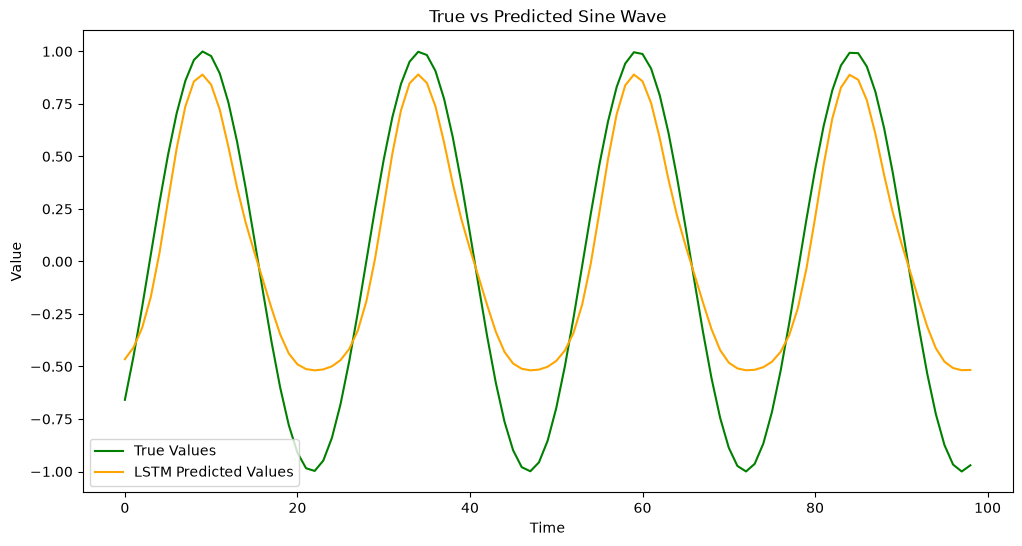

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Generate a sine wave
def generate_sine_wave(samples, step):
    x = np.linspace(0, samples * step, samples)
    y = np.sin(x)
    return x, y

# Parameters
samples = 1000
time_steps = 10  # Number of time steps in each sequence
step = 0.25  # Step size

# Generate sine wave data
x, y = generate_sine_wave(samples, step)

# Prepare the data for LSTM
def prepare_data(y, time_steps):
    X, Y = [], []
    for i in range(len(y) - time_steps):
        X.append(y[i:i + time_steps])
        Y.append(y[i + time_steps])
    return np.array(X), np.array(Y)

X, Y = prepare_data(y, time_steps)

# Split into training and testing
train_size = int(0.9 * len(X))
X_train, Y_train = X[:train_size], Y[:train_size]
X_test, Y_test = X[train_size:], Y[train_size:]

# Reshape data to fit LSTM input format [samples, time_steps, features]
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# Build the LSTM model
model = Sequential([
    LSTM(5, activation='tanh', return_sequences=False, input_shape=(time_steps, 1)),
    Dense(1)
])

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Train the model
history = model.fit(X_train, Y_train, epochs=3, batch_size=8, validation_data=(X_test, Y_test))

# Predict
Y_pred = model.predict(X_test)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(range(len(Y_test)), Y_test, label="True Values", color="green")
plt.plot(range(len(Y_pred)), Y_pred, label="LSTM Predicted Values", color="orange")
plt.title("True vs Predicted Sine Wave")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.show()


- Try different epochs, sizes of lstm modules # LSTM(5), 1, 10 and report the results

## Experimentos reutilizables y reporte de resultados

Ejecuta primero la celda original para definir `generate_sine_wave` y `prepare_data`. `run_lstm_experiment(samples, time_step, step, train_size)` reutiliza esas funciones y conserva la arquitectura y los valores predeterminados del ejercicio (5 unidades, 3 épocas, lotes de 8). `train_size` acepta una proporción decimal entre 0 y 1 o un número entero de secuencias; la separación es cronológica y no se mezclan las muestras durante el entrenamiento.

Las figuras de predicción e historial se guardan como PNG con un identificador único en la carpeta configurada. Como en el ejercicio original, el conjunto de prueba se usa también como validación: sus métricas son descriptivas, no una evaluación independiente para seleccionar hiperparámetros.

`evaluate_lstm_metrics(y_true, y_pred)` devuelve un DataFrame con MAE, MSE, RMSE, R², MAPE y sMAPE. Acepta vectores o columnas `(n, 1)` de pronósticos a un paso, en la escala original. MAPE excluye objetivos con valor absoluto menor o igual a `1e-8`, informa cuántos excluye y devuelve NaN si no hay valores válidos. R² no está definido con menos de dos observaciones o un objetivo constante. sMAPE asigna error cero cuando ambos valores son cero.

Con `export_format="text"`, `"markdown"` o `"html"`, devuelve una cadena lista para copiar; `export_path` permite además guardarla en UTF-8. Los cálculos conservan su precisión y solo la exportación redondea a seis decimales.

In [2]:
import sys
from datetime import datetime
from numbers import Integral, Real
from pathlib import Path
from uuid import uuid4

import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Permite importar src al iniciar Jupyter desde la carpeta del notebook.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Ejecuta el notebook dentro del proyecto deep-learning-labs.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import PROJECT_PATH
from src.utils import logger as log

logger = log.LOGGER
config = log.CONFIG
figure_directory = Path(config.paths.reports.figures)
if not figure_directory.exists():
    logger.warning("La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.")
    figure_directory = PROJECT_PATH / figure_directory
figure_directory.mkdir(parents=True, exist_ok=True)


def evaluate_lstm_metrics(y_true, y_pred, *, export_format=None, export_path=None):
    """Devuelve la tabla de regresión o su representación text, markdown o html.

    export_path requiere export_format; los directorios de destino se crean.
    NaN indica una métrica no definida y se acompaña de una advertencia.
    """
    formats = {None, "text", "markdown", "html"}
    if export_format not in formats:
        raise ValueError("export_format debe ser None, 'text', 'markdown' o 'html'.")
    if export_path is not None and export_format is None:
        raise ValueError("Indica export_format para guardar la tabla en export_path.")

    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)
    for name, values in (("y_true", actual), ("y_pred", predicted)):
        if values.ndim not in (1, 2) or (values.ndim == 2 and values.shape[1] != 1):
            raise ValueError(f"{name} debe tener forma (n,) o (n, 1).")
        if values.size == 0 or not np.isfinite(values).all():
            raise ValueError(f"{name} debe contener valores finitos y no estar vacío.")
    actual, predicted = actual.reshape(-1), predicted.reshape(-1)
    if actual.shape != predicted.shape:
        raise ValueError("y_true y y_pred deben tener la misma cantidad de observaciones.")

    mse = mean_squared_error(actual, predicted)
    absolute_error = np.abs(actual - predicted)
    valid_mape = np.abs(actual) > 1e-8
    excluded = int((~valid_mape).sum())
    if excluded:
        logger.warning("MAPE excluye %d de %d objetivos nulos o cercanos a cero.", excluded, actual.size)
    mape = (
        float(np.mean(absolute_error[valid_mape] / np.abs(actual[valid_mape])) * 100)
        if valid_mape.any() else np.nan
    )
    if actual.size < 2 or np.all(actual == actual[0]):
        logger.warning("R² no está definido para menos de dos datos o un objetivo constante.")
        r_squared = np.nan
    else:
        r_squared = r2_score(actual, predicted)
    denominator = np.abs(actual) + np.abs(predicted)
    smape = 200 * np.mean(np.divide(
        absolute_error, denominator,
        out=np.zeros_like(absolute_error), where=denominator != 0,
    ))
    table = pd.DataFrame([
        ("MAE", mean_absolute_error(actual, predicted), "Menor es mejor"),
        ("MSE", mse, "Menor es mejor"),
        ("RMSE", np.sqrt(mse), "Menor es mejor"),
        ("R²", r_squared, "Mejor: 1; puede ser negativo"),
        ("MAPE (%)", mape, f"Menor es mejor; excluidos: {excluded}/{actual.size}"),
        ("sMAPE (%)", smape, "Menor es mejor; rango: 0 a 200"),
    ], columns=["Métrica", "Valor", "Interpretación"])
    if export_format is None:
        return table

    if export_format == "text":
        exported = table.to_string(index=False, float_format=lambda value: f"{value:.6f}")
    elif export_format == "markdown":
        exported = table.to_markdown(index=False, floatfmt=".6f")
    else:
        exported = table.to_html(index=False, float_format=lambda value: f"{value:.6f}")
    if export_path is not None:
        destination = Path(export_path)
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_text(exported, encoding="utf-8")
        logger.info("Tabla de métricas guardada en %s", destination.resolve())
    return exported


def run_lstm_experiment(
    samples, time_step, step, train_size, *,
    epochs=3, lstm_units=5, batch_size=8, seed=42, show=True,
):
    """Repite el ejercicio y devuelve modelo, historial, métricas y rutas de figuras.

    train_size: proporción real (0, 1) o cantidad entera de secuencias.
    epochs y lstm_units permiten las comparaciones propuestas en el ejercicio.
    """
    for name, value in (
        ("samples", samples), ("time_step", time_step), ("epochs", epochs),
        ("lstm_units", lstm_units), ("batch_size", batch_size),
    ):
        if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
            raise ValueError(f"{name} debe ser un entero positivo.")
    if samples - time_step < 2:
        raise ValueError("samples - time_step debe dejar al menos dos secuencias.")
    if isinstance(step, bool) or not isinstance(step, Real) or not np.isfinite(step) or step <= 0:
        raise ValueError("step debe ser un número finito positivo.")
    sequence_count = samples - time_step
    if isinstance(train_size, bool):
        raise ValueError("train_size no puede ser booleano.")
    if isinstance(train_size, Integral):
        split = int(train_size)
    elif isinstance(train_size, Real) and np.isfinite(train_size) and 0 < train_size < 1:
        split = int(train_size * sequence_count)
    else:
        raise ValueError("train_size debe ser una proporción (0, 1) o un entero positivo.")
    if not 0 < split < sequence_count:
        raise ValueError("train_size debe dejar secuencias tanto para entrenamiento como para prueba.")
    if isinstance(seed, bool) or not isinstance(seed, Integral) or not 0 <= seed < 2**32:
        raise ValueError("seed debe ser un entero entre 0 y 2**32 - 1.")

    tf.keras.utils.set_random_seed(int(seed))
    wave_x, wave_y = generate_sine_wave(samples, step)
    features, targets = prepare_data(wave_y, time_step)
    features = features.reshape((len(features), time_step, 1))
    train_x, test_x = features[:split], features[split:]
    train_y, test_y = targets[:split], targets[split:]
    experiment_model = Sequential([
        tf.keras.Input(shape=(time_step, 1)),
        LSTM(lstm_units, activation="tanh", return_sequences=False),
        Dense(1),
    ])
    experiment_model.compile(optimizer="adam", loss="mse")
    logger.info(
        "LSTM: samples=%d, time_step=%d, step=%s, train=%d, test=%d, units=%d, epochs=%d",
        samples, time_step, step, split, len(test_y), lstm_units, epochs,
    )
    experiment_history = experiment_model.fit(
        train_x, train_y, epochs=epochs, batch_size=batch_size,
        validation_data=(test_x, test_y), shuffle=False, verbose=0,
    )
    predictions = experiment_model.predict(test_x, verbose=0).reshape(-1)
    metrics = evaluate_lstm_metrics(test_y, predictions)
    run_id = f"lstm_{datetime.now():%Y%m%d_%H%M%S_%f}_{uuid4().hex[:8]}"
    figure_paths = {
        "predictions": figure_directory / f"{run_id}_predictions.png",
        "loss": figure_directory / f"{run_id}_loss.png",
    }
    test_time = wave_x[time_step + split:]
    prediction_figure, axis = plt.subplots(figsize=(12, 6))
    axis.plot(test_time, test_y, label="Valores reales", color="green")
    axis.plot(test_time, predictions, label="Predicción LSTM", color="orange")
    axis.set(title="Onda seno: valores reales y predicción", xlabel="Tiempo", ylabel="Valor")
    axis.legend()
    loss_figure, axis = plt.subplots(figsize=(10, 5))
    epoch_numbers = range(1, epochs + 1)
    axis.plot(epoch_numbers, experiment_history.history["loss"], label="Entrenamiento")
    axis.plot(epoch_numbers, experiment_history.history["val_loss"], label="Validación (prueba)")
    axis.set(title="Historial de pérdida", xlabel="Época", ylabel="MSE")
    axis.legend()
    for figure, destination in (
        (prediction_figure, figure_paths["predictions"]),
        (loss_figure, figure_paths["loss"]),
    ):
        figure.tight_layout()
        figure.savefig(destination, dpi=150, bbox_inches="tight")
        logger.info("Figura guardada en %s", destination.resolve())
    if show:
        plt.show()
    plt.close(prediction_figure)
    plt.close(loss_figure)
    return {
        "model": experiment_model,
        "history": experiment_history,
        "y_true": test_y,
        "y_pred": predictions,
        "test_time": test_time,
        "metrics": metrics,
        "figure_paths": figure_paths,
        "run_id": run_id,
    }


2026-11-24 16:14:45 [WARNING] La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.


2026-11-24 16:14:45 [INFO] LSTM: samples=1000, time_step=10, step=0.25, train=891, test=99, units=5, epochs=3
2026-11-24 16:14:49 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_161449_728867_3d63e1a5_predictions.png
2026-11-24 16:14:50 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_161449_728867_3d63e1a5_loss.png


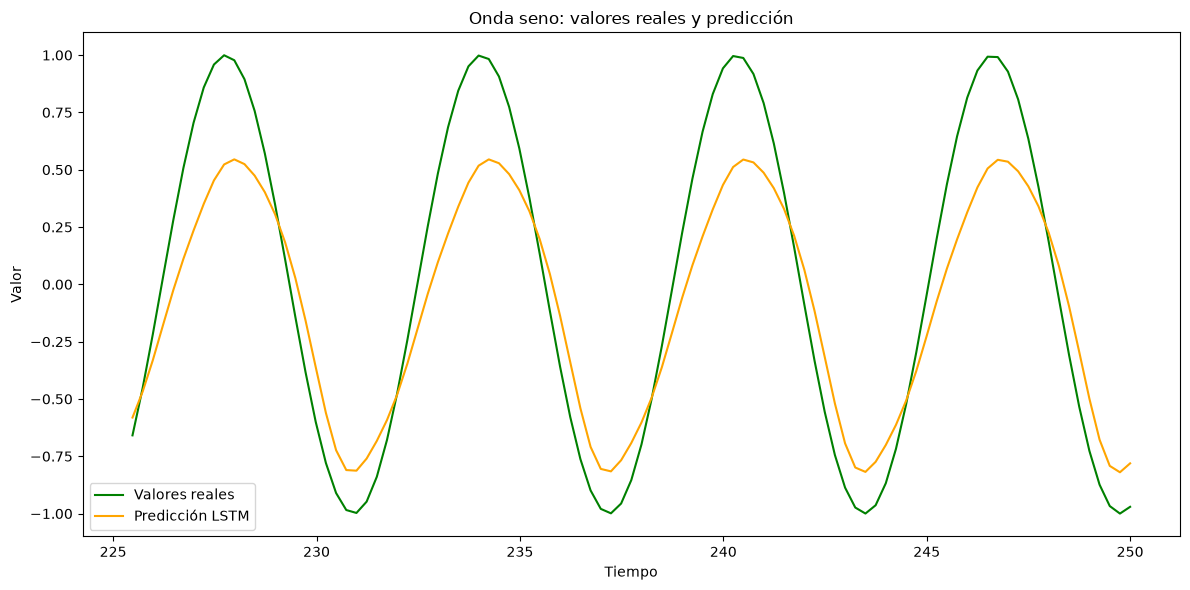

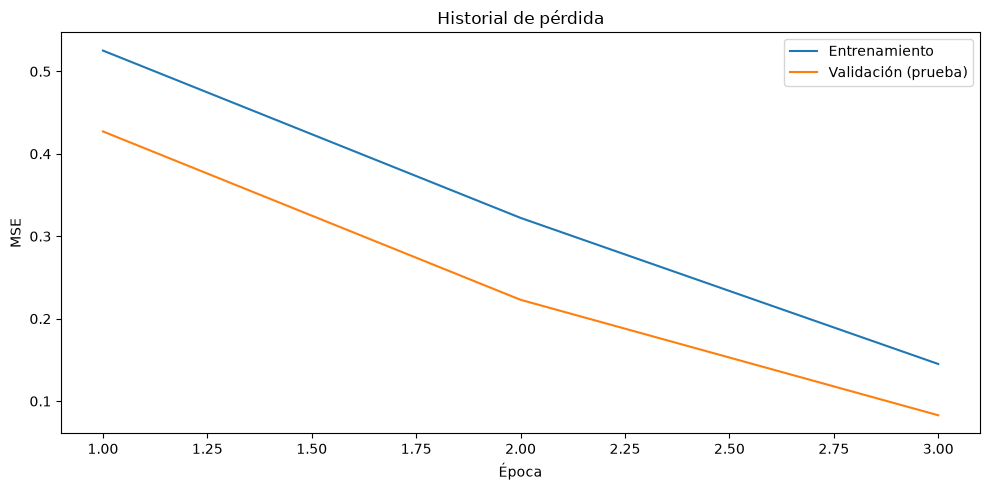

,Métrica,Valor,Interpretación
0,MAE,0.248277,Menor es mejor
1,MSE,0.082810,Menor es mejor
2,RMSE,0.287767,Menor es mejor
3,R²,0.833238,Mejor: 1; puede ser negativo
4,MAPE (%),106.570586,Menor es mejor; excluidos: 0/99
5,sMAPE (%),65.254535,Menor es mejor; rango: 0 a 200


2026-11-24 16:14:50 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_161449_728867_3d63e1a5_metrics.txt
2026-11-24 16:14:50 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_161449_728867_3d63e1a5_metrics.md
2026-11-24 16:14:50 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_161449_728867_3d63e1a5_metrics.html


| Métrica   |      Valor | Interpretación                  |
|:----------|-----------:|:--------------------------------|
| MAE       |   0.248277 | Menor es mejor                  |
| MSE       |   0.082810 | Menor es mejor                  |
| RMSE      |   0.287767 | Menor es mejor                  |
| R²        |   0.833238 | Mejor: 1; puede ser negativo    |
| MAPE (%)  | 106.570586 | Menor es mejor; excluidos: 0/99 |
| sMAPE (%) |  65.254535 | Menor es mejor; rango: 0 a 200  |


In [3]:
from IPython.display import display

result = run_lstm_experiment(
    samples=1000, time_step=10, step=0.25, train_size=0.9,
    epochs=3, lstm_units=5,
)
display(result["metrics"])

report_directory = figure_directory.parent / "tables"
exports = {}
for export_format, extension in (("text", "txt"), ("markdown", "md"), ("html", "html")):
    exports[export_format] = evaluate_lstm_metrics(
        result["y_true"], result["y_pred"],
        export_format=export_format,
        export_path=report_directory / f"{result['run_id']}_metrics.{extension}",
    )
print(exports["markdown"])


2026-11-24 16:21:07 [INFO] LSTM: samples=2000, time_step=10, step=0.25, train=1592, test=398, units=5, epochs=5
2026-11-24 16:21:18 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_162118_071702_a7fc1542_predictions.png
2026-11-24 16:21:18 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_162118_071702_a7fc1542_loss.png


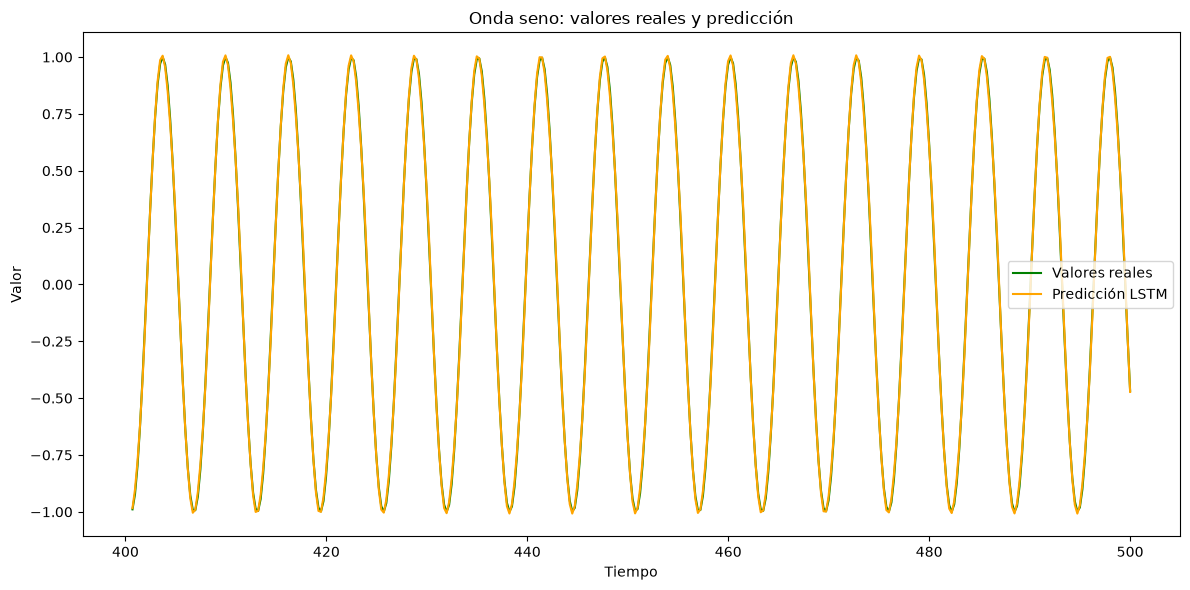

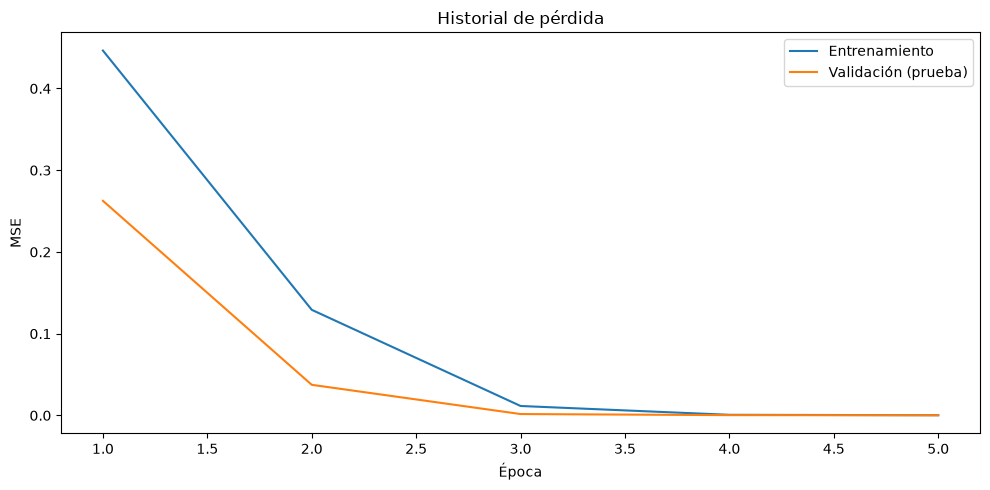

,Métrica,Valor,Interpretación
0,MAE,0.010968,Menor es mejor
1,MSE,0.000172,Menor es mejor
2,RMSE,0.013132,Menor es mejor
3,R²,0.999653,Mejor: 1; puede ser negativo
4,MAPE (%),5.659896,Menor es mejor; excluidos: 0/398
5,sMAPE (%),5.076742,Menor es mejor; rango: 0 a 200


2026-11-24 16:21:18 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_162118_071702_a7fc1542_metrics.txt
2026-11-24 16:21:19 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_162118_071702_a7fc1542_metrics.md


| Métrica   |    Valor | Interpretación                   |
|:----------|---------:|:---------------------------------|
| MAE       | 0.010968 | Menor es mejor                   |
| MSE       | 0.000172 | Menor es mejor                   |
| RMSE      | 0.013132 | Menor es mejor                   |
| R²        | 0.999653 | Mejor: 1; puede ser negativo     |
| MAPE (%)  | 5.659896 | Menor es mejor; excluidos: 0/398 |
| sMAPE (%) | 5.076742 | Menor es mejor; rango: 0 a 200   |


In [6]:
result = run_lstm_experiment(
    samples=2000, time_step=10, step=0.25, train_size=0.8,
    epochs=5, lstm_units=5,
)
display(result["metrics"])

report_directory = figure_directory.parent / "tables"
exports = {}
for export_format, extension in (("text", "txt"),("markdown", "md")):
    exports[export_format] = evaluate_lstm_metrics(
        result["y_true"], result["y_pred"],
        export_format=export_format,
        export_path=report_directory / f"{result['run_id']}_metrics.{extension}",
    )
print(exports["markdown"])

2026-11-24 16:23:30 [INFO] LSTM: samples=2000, time_step=5, step=0.5, train=1496, test=499, units=10, epochs=5
2026-11-24 16:23:40 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_162339_727340_5932939d_predictions.png
2026-11-24 16:23:40 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_162339_727340_5932939d_loss.png


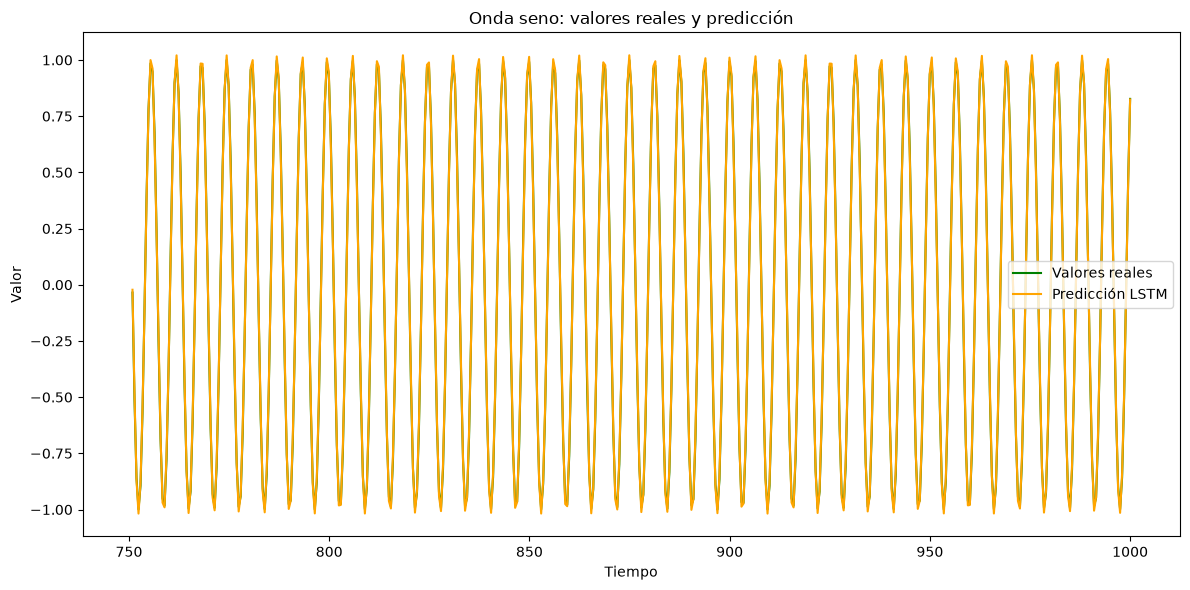

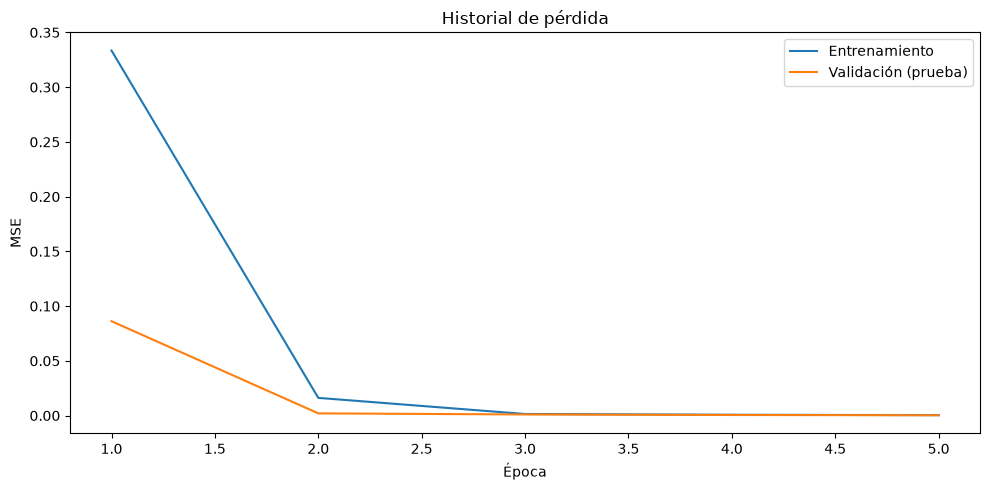

,Métrica,Valor,Interpretación
0,MAE,0.014290,Menor es mejor
1,MSE,0.000266,Menor es mejor
2,RMSE,0.016309,Menor es mejor
3,R²,0.999467,Mejor: 1; puede ser negativo
4,MAPE (%),5.514197,Menor es mejor; excluidos: 0/499
5,sMAPE (%),5.455340,Menor es mejor; rango: 0 a 200


2026-11-24 16:23:40 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_162339_727340_5932939d_metrics.txt
2026-11-24 16:23:40 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_162339_727340_5932939d_metrics.md


| Métrica   |    Valor | Interpretación                   |
|:----------|---------:|:---------------------------------|
| MAE       | 0.014290 | Menor es mejor                   |
| MSE       | 0.000266 | Menor es mejor                   |
| RMSE      | 0.016309 | Menor es mejor                   |
| R²        | 0.999467 | Mejor: 1; puede ser negativo     |
| MAPE (%)  | 5.514197 | Menor es mejor; excluidos: 0/499 |
| sMAPE (%) | 5.455340 | Menor es mejor; rango: 0 a 200   |


In [7]:
result = run_lstm_experiment(
    samples=2000, time_step=5, step=0.5, train_size=0.75,
    epochs=5, lstm_units=10,
)
display(result["metrics"])

report_directory = figure_directory.parent / "tables"
exports = {}
for export_format, extension in (("text", "txt"),("markdown", "md")):
    exports[export_format] = evaluate_lstm_metrics(
        result["y_true"], result["y_pred"],
        export_format=export_format,
        export_path=report_directory / f"{result['run_id']}_metrics.{extension}",
    )
print(exports["markdown"])

2026-11-24 17:06:28 [INFO] LSTM: samples=1000, time_step=10, step=0.25, train=891, test=99, units=30, epochs=3
2026-11-24 17:06:38 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_170636_822840_bc64bbf4_predictions.png
2026-11-24 17:06:38 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_170636_822840_bc64bbf4_loss.png


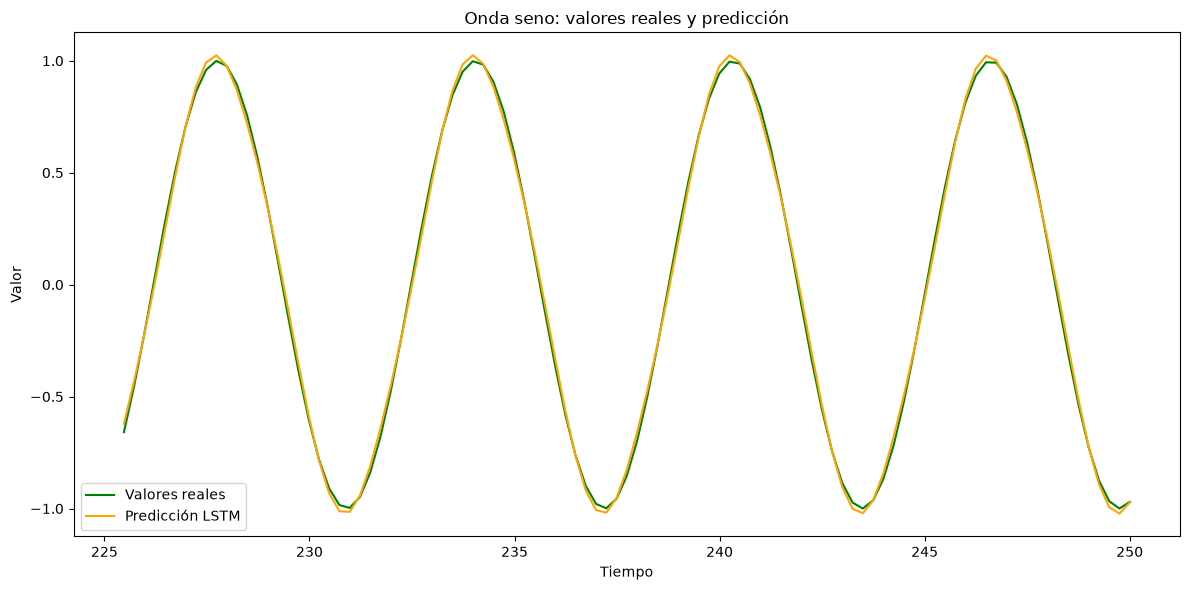

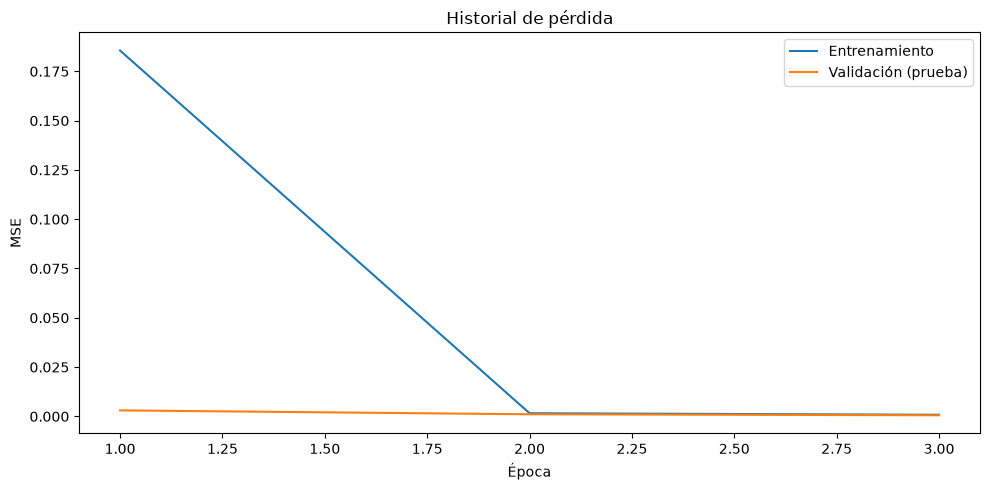

,Métrica,Valor,Interpretación
0,MAE,0.021008,Menor es mejor
1,MSE,0.000565,Menor es mejor
2,RMSE,0.023761,Menor es mejor
3,R²,0.998863,Mejor: 1; puede ser negativo
4,MAPE (%),12.343703,Menor es mejor; excluidos: 0/99
5,sMAPE (%),9.731429,Menor es mejor; rango: 0 a 200


2026-11-24 17:06:38 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_170636_822840_bc64bbf4_metrics.txt
2026-11-24 17:06:38 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_170636_822840_bc64bbf4_metrics.md


| Métrica   |     Valor | Interpretación                  |
|:----------|----------:|:--------------------------------|
| MAE       |  0.021008 | Menor es mejor                  |
| MSE       |  0.000565 | Menor es mejor                  |
| RMSE      |  0.023761 | Menor es mejor                  |
| R²        |  0.998863 | Mejor: 1; puede ser negativo    |
| MAPE (%)  | 12.343703 | Menor es mejor; excluidos: 0/99 |
| sMAPE (%) |  9.731429 | Menor es mejor; rango: 0 a 200  |


In [8]:
result = run_lstm_experiment(
    samples=1000, time_step=10, step=0.25, train_size=0.9,
    epochs=3, lstm_units=30,
)
display(result["metrics"])

report_directory = figure_directory.parent / "tables"
exports = {}
for export_format, extension in (("text", "txt"),("markdown", "md")):
    exports[export_format] = evaluate_lstm_metrics(
        result["y_true"], result["y_pred"],
        export_format=export_format,
        export_path=report_directory / f"{result['run_id']}_metrics.{extension}",
    )
print(exports["markdown"])

2026-11-24 17:30:13 [INFO] LSTM: samples=1000, time_step=10, step=0.25, train=891, test=99, units=10, epochs=3


2026-11-24 17:30:18 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_173018_077529_72b788cb_predictions.png
2026-11-24 17:30:18 [INFO] Figura guardada en D:\deep-learning-labs\reports\figures\lstm_20261124_173018_077529_72b788cb_loss.png


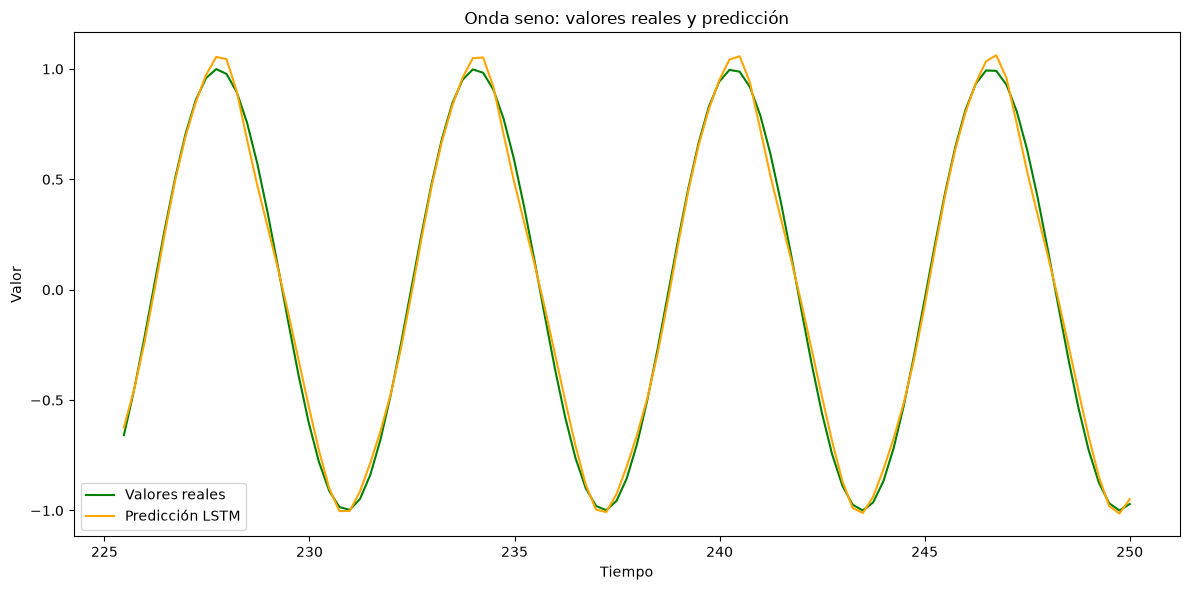

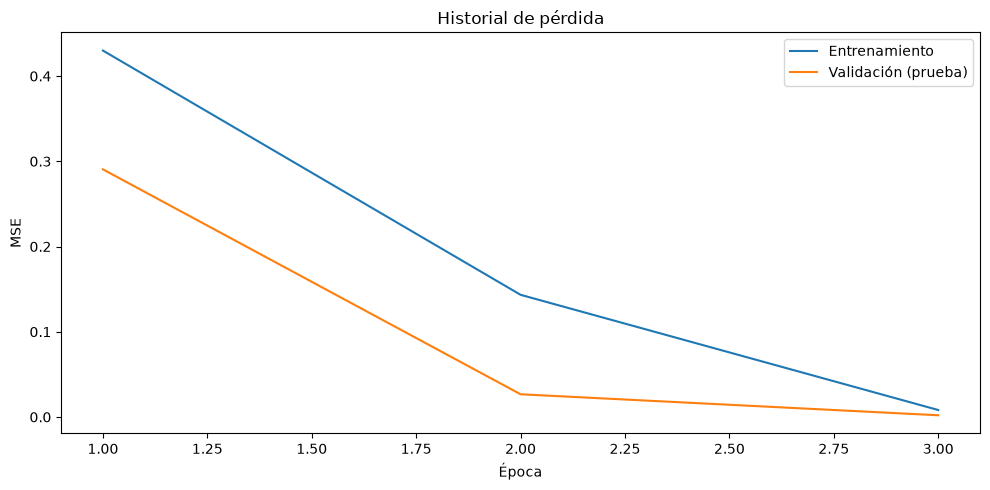

,Métrica,Valor,Interpretación
0,MAE,0.035890,Menor es mejor
1,MSE,0.001988,Menor es mejor
2,RMSE,0.044583,Menor es mejor
3,R²,0.995997,Mejor: 1; puede ser negativo
4,MAPE (%),16.210677,Menor es mejor; excluidos: 0/99
5,sMAPE (%),12.859084,Menor es mejor; rango: 0 a 200


2026-11-24 17:30:19 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_173018_077529_72b788cb_metrics.txt
2026-11-24 17:30:19 [INFO] Tabla de métricas guardada en D:\deep-learning-labs\reports\tables\lstm_20261124_173018_077529_72b788cb_metrics.md


| Métrica   |     Valor | Interpretación                  |
|:----------|----------:|:--------------------------------|
| MAE       |  0.035890 | Menor es mejor                  |
| MSE       |  0.001988 | Menor es mejor                  |
| RMSE      |  0.044583 | Menor es mejor                  |
| R²        |  0.995997 | Mejor: 1; puede ser negativo    |
| MAPE (%)  | 16.210677 | Menor es mejor; excluidos: 0/99 |
| sMAPE (%) | 12.859084 | Menor es mejor; rango: 0 a 200  |


In [9]:
result = run_lstm_experiment(
    samples=1000, time_step=10, step=0.25, train_size=0.9,
    epochs=3, lstm_units=10,
)
display(result["metrics"])

report_directory = figure_directory.parent / "tables"
exports = {}
for export_format, extension in (("text", "txt"),("markdown", "md")):
    exports[export_format] = evaluate_lstm_metrics(
        result["y_true"], result["y_pred"],
        export_format=export_format,
        export_path=report_directory / f"{result['run_id']}_metrics.{extension}",
    )
print(exports["markdown"])